In [1]:
# Import pandas for working with tables and datasets
import pandas as pd

# Import numpy for numerical calculations
import numpy as np

# Import matplotlib for creating graphs
import matplotlib.pyplot as plt

# Import train_test_split to divide the dataset into training, validation and test sets
from sklearn.model_selection import train_test_split

# Import ColumnTransformer to apply different preprocessing to different columns
from sklearn.compose import ColumnTransformer

# Import Pipeline to combine multiple preprocessing steps
from sklearn.pipeline import Pipeline

# Import SimpleImputer to handle missing values
from sklearn.impute import SimpleImputer

# Import OneHotEncoder to convert categorical values into numbers
from sklearn.preprocessing import OneHotEncoder

# Import StandardScaler to standardize numerical features
from sklearn.preprocessing import StandardScaler

# Import SelectKBest to select the most useful features
from sklearn.feature_selection import SelectKBest

# Import f_classif to calculate the relationship between features and the target
from sklearn.feature_selection import f_classif

# Import LogisticRegression for our main prediction model
from sklearn.linear_model import LogisticRegression

# Import LinearDiscriminantAnalysis for model comparison
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# Import accuracy to measure overall correct predictions
from sklearn.metrics import accuracy_score

# Import precision to measure how many predicted delays were actually delays
from sklearn.metrics import precision_score

# Import recall to measure how many actual delays were detected
from sklearn.metrics import recall_score

# Import F1 score to balance precision and recall
from sklearn.metrics import f1_score

# Import ROC-AUC to measure how well the model separates delayed and non-delayed projects
from sklearn.metrics import roc_auc_score

# Import confusion_matrix to see correct and incorrect predictions
from sklearn.metrics import confusion_matrix

# Import ConfusionMatrixDisplay to display the confusion matrix as a graph
from sklearn.metrics import ConfusionMatrixDisplay

ModuleNotFoundError: No module named 'matplotlib'

# Predictive Analytics System for Early Detection of Land Acquisition Delays

## MoSPI Infrastructure Project Analysis

This notebook contains the data analysis, preprocessing, feature engineering,
feature selection, model training, model comparison and final evaluation.

In [ ]:
# Read the MoSPI project dataset from the CSV file
df = pd.read_csv("SIH26017_MoSPI_1477_projects.csv")

# Display the number of rows and columns in the dataset
print("Dataset shape:", df.shape)

# Display the first five rows to understand the data
df.head()

Dataset shape: (1477, 21)


,project_code,project_name,sector,agency,state,approval_date,orig_commissioning_date,rev_commissioning_date,ant_commissioning_date,orig_cost_cr,...,ant_cost_cr,cumulative_exp_cr,physical_progress_pct,delay_months,is_delayed,cost_overrun_pct,expenditure_ratio,source_page,source_dataset,created_at
0,N04000073,CONSTRUCTION OF NEW INTEGRATED TERMINAL BUILDI...,ROAD TRANSPORT AND HIGHWAYS,AAI,ANDAMAN AND NICOBAR ISLANDS,01/10/13,01/09/18,NaN,01/06/23,417.23,...,707.73,698.80,100.00,57,1,69.63,1.6749,42,MoSPI_Flash_Report_Feb2025,29/09/26 15:33
1,N22000584,LUDHIANA KILA RAIPUR (19 KMS) WITH FREIGHT LIN...,ROAD TRANSPORT AND HIGHWAYS,NR,ANDAMAN AND NICOBAR ISLANDS,01/03/19,01/03/25,NaN,01/10/25,235.72,...,235.72,48.62,52.00,7,1,0.00,0.2063,42,MoSPI_Flash_Report_Feb2025,29/09/26 15:33
2,N24000745,"LANE WITH HARD SHOLDER , REHABILITATION AND UP...",ROAD TRANSPORT AND HIGHWAYS,NHIDCL,ANDAMAN AND NICOBAR ISLANDS,01/03/17,01/12/19,NaN,01/09/24,409.85,...,409.85,214.23,94.59,57,1,0.00,0.5227,42,MoSPI_Flash_Report_Feb2025,29/09/26 15:33
3,N24000749,GRADATION OF SECTION FROM KM 206.00 TO KM 242....,ROAD TRANSPORT AND HIGHWAYS,NHIDCL,ANDAMAN AND NICOBAR ISLANDS,01/03/18,01/09/20,NaN,01/12/24,234.27,...,234.27,126.50,80.26,51,1,0.00,0.5400,42,MoSPI_Flash_Report_Feb2025,29/09/26 15:33
4,N24000820,Rehabilitation and up gradation to 2 lane with...,ROAD TRANSPORT AND HIGHWAYS,MoRTH,ANDAMAN AND NICOBAR ISLANDS,01/11/17,01/11/19,NaN,01/11/19,237.80,...,238.00,222.13,98.23,0,0,0.08,0.9341,42,MoSPI_Flash_Report_Feb2025,29/09/26 15:33


In [ ]:
# Display the names of all columns in the dataset
print("Columns:")
print(df.columns.tolist())

# Display the data type of every column
print("\nData types:")
print(df.dtypes)

# Display the first five rows of the dataset
print("\nFirst five rows:")
display(df.head())

Columns:
['project_code', 'project_name', 'sector', 'agency', 'state', 'approval_date', 'orig_commissioning_date', 'rev_commissioning_date', 'ant_commissioning_date', 'orig_cost_cr', 'rev_cost_cr', 'ant_cost_cr', 'cumulative_exp_cr', 'physical_progress_pct', 'delay_months', 'is_delayed', 'cost_overrun_pct', 'expenditure_ratio', 'source_page', 'source_dataset', 'created_at']

Data types:
project_code                   str
project_name                   str
sector                         str
agency                         str
state                          str
approval_date                  str
orig_commissioning_date        str
rev_commissioning_date     float64
ant_commissioning_date         str
orig_cost_cr               float64
rev_cost_cr                float64
ant_cost_cr                float64
cumulative_exp_cr          float64
physical_progress_pct      float64
delay_months                 int64
is_delayed                   int64
cost_overrun_pct           float64
expenditure_rat

,project_code,project_name,sector,agency,state,approval_date,orig_commissioning_date,rev_commissioning_date,ant_commissioning_date,orig_cost_cr,...,ant_cost_cr,cumulative_exp_cr,physical_progress_pct,delay_months,is_delayed,cost_overrun_pct,expenditure_ratio,source_page,source_dataset,created_at
0,N04000073,CONSTRUCTION OF NEW INTEGRATED TERMINAL BUILDI...,ROAD TRANSPORT AND HIGHWAYS,AAI,ANDAMAN AND NICOBAR ISLANDS,01/10/13,01/09/18,NaN,01/06/23,417.23,...,707.73,698.80,100.00,57,1,69.63,1.6749,42,MoSPI_Flash_Report_Feb2025,29/09/26 15:33
1,N22000584,LUDHIANA KILA RAIPUR (19 KMS) WITH FREIGHT LIN...,ROAD TRANSPORT AND HIGHWAYS,NR,ANDAMAN AND NICOBAR ISLANDS,01/03/19,01/03/25,NaN,01/10/25,235.72,...,235.72,48.62,52.00,7,1,0.00,0.2063,42,MoSPI_Flash_Report_Feb2025,29/09/26 15:33
2,N24000745,"LANE WITH HARD SHOLDER , REHABILITATION AND UP...",ROAD TRANSPORT AND HIGHWAYS,NHIDCL,ANDAMAN AND NICOBAR ISLANDS,01/03/17,01/12/19,NaN,01/09/24,409.85,...,409.85,214.23,94.59,57,1,0.00,0.5227,42,MoSPI_Flash_Report_Feb2025,29/09/26 15:33
3,N24000749,GRADATION OF SECTION FROM KM 206.00 TO KM 242....,ROAD TRANSPORT AND HIGHWAYS,NHIDCL,ANDAMAN AND NICOBAR ISLANDS,01/03/18,01/09/20,NaN,01/12/24,234.27,...,234.27,126.50,80.26,51,1,0.00,0.5400,42,MoSPI_Flash_Report_Feb2025,29/09/26 15:33
4,N24000820,Rehabilitation and up gradation to 2 lane with...,ROAD TRANSPORT AND HIGHWAYS,MoRTH,ANDAMAN AND NICOBAR ISLANDS,01/11/17,01/11/19,NaN,01/11/19,237.80,...,238.00,222.13,98.23,0,0,0.08,0.9341,42,MoSPI_Flash_Report_Feb2025,29/09/26 15:33


In [ ]:
# Count the number of missing values in each column
missing_values = df.isnull().sum()

# Display the missing value count for every column
print(missing_values)

project_code                  0
project_name                  0
sector                        0
agency                        0
state                         0
approval_date                 0
orig_commissioning_date       0
rev_commissioning_date     1477
ant_commissioning_date        0
orig_cost_cr                  0
rev_cost_cr                1132
ant_cost_cr                   0
cumulative_exp_cr             0
physical_progress_pct         0
delay_months                  0
is_delayed                    0
cost_overrun_pct              0
expenditure_ratio             0
source_page                   0
source_dataset                0
created_at                    0
dtype: int64


In [ ]:
# Count the number of delayed and non-delayed projects
target_counts = df["is_delayed"].value_counts()

# Display the number of projects in each class
print(target_counts)

# Calculate and display the percentage of each class
print("\nTarget distribution (%):")
print(df["is_delayed"].value_counts(normalize=True) * 100)

is_delayed
1    962
0    515
Name: count, dtype: int64

Target distribution (%):
is_delayed
1    65.132024
0    34.867976
Name: proportion, dtype: float64


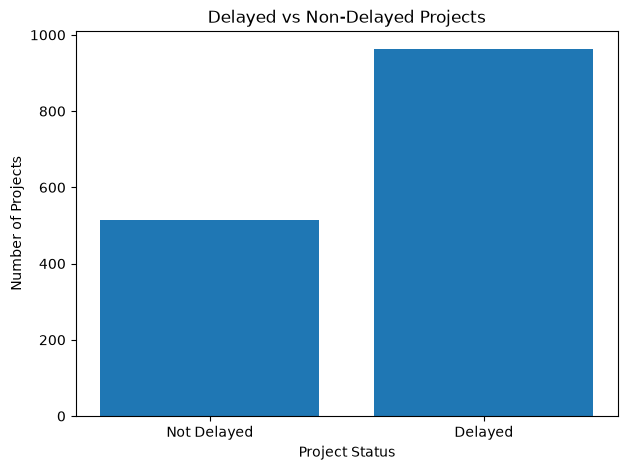

In [ ]:
# Count projects in each target class
target_counts = df["is_delayed"].value_counts().sort_index()

# Create labels for the two target classes
labels = ["Not Delayed", "Delayed"]

# Set the size of the graph
plt.figure(figsize=(7, 5))

# Create a bar chart
plt.bar(labels, target_counts.values)

# Label the x-axis
plt.xlabel("Project Status")

# Label the y-axis
plt.ylabel("Number of Projects")

# Add a title to the graph
plt.title("Delayed vs Non-Delayed Projects")

# Display the graph
plt.show()

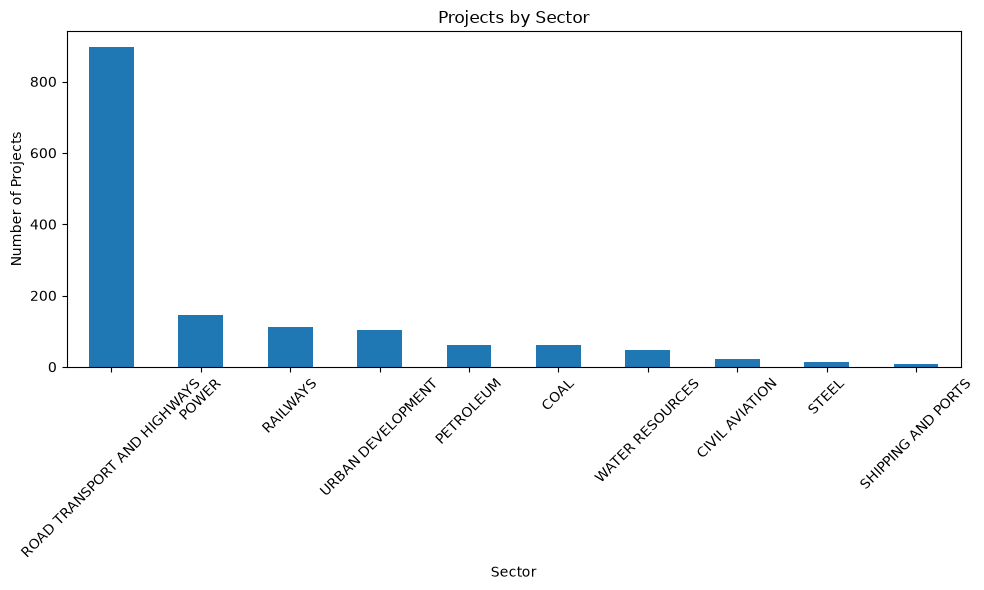

In [ ]:
# Count the number of projects in each sector
sector_counts = df["sector"].value_counts()

# Set the size of the graph
plt.figure(figsize=(10, 6))

# Create a bar chart for project count by sector
sector_counts.plot(kind="bar")

# Label the x-axis
plt.xlabel("Sector")

# Label the y-axis
plt.ylabel("Number of Projects")

# Add a title to the graph
plt.title("Projects by Sector")

# Rotate sector names for better readability
plt.xticks(rotation=45)

# Adjust the graph layout
plt.tight_layout()

# Display the graph
plt.show()


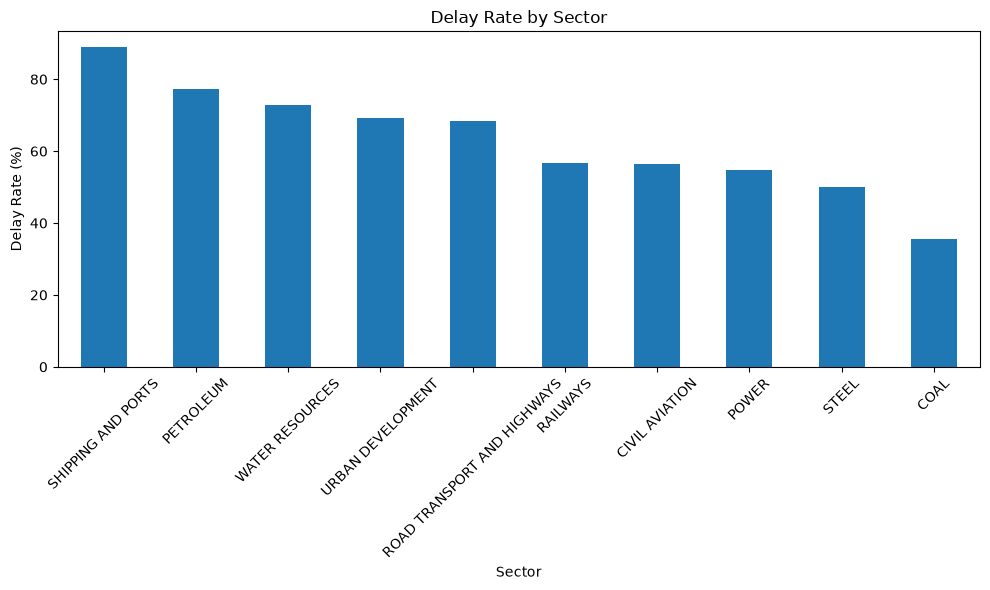

In [ ]:
# Group projects by sector and calculate the average delay value
sector_delay_rate = (
    df.groupby("sector")["is_delayed"]
    .mean()
    .sort_values(ascending=False)
)

# Convert the delay rate from decimal to percentage
sector_delay_rate = sector_delay_rate * 100

# Set the size of the graph
plt.figure(figsize=(10, 6))

# Create a bar chart for delay rate by sector
sector_delay_rate.plot(kind="bar")

# Label the x-axis
plt.xlabel("Sector")

# Label the y-axis
plt.ylabel("Delay Rate (%)")

# Add a title to the graph
plt.title("Delay Rate by Sector")

# Rotate sector names for better readability
plt.xticks(rotation=45)

# Adjust the graph layout
plt.tight_layout()

# Display the graph
plt.show()

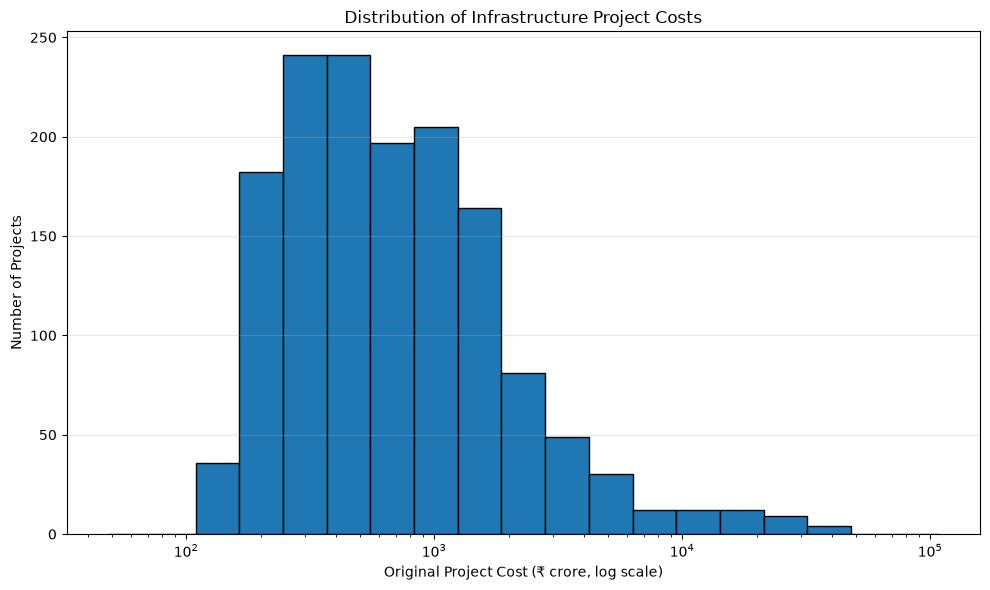

In [ ]:
#histogram 

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Convert project costs to numeric values
cost_data = pd.to_numeric(
    df["orig_cost_cr"],
    errors="coerce"
).dropna()

# Remove zero and negative values because logarithmic bins
# require strictly positive project costs
cost_data = cost_data[cost_data > 0]

# Create logarithmically spaced bin boundaries
# This gives wider intervals for larger project costs
bins = np.logspace(
    np.log10(cost_data.min()),
    np.log10(cost_data.max()),
    20
)

# Create the histogram using logarithmic bins
plt.figure(figsize=(10, 6))
plt.hist(
    cost_data,
    bins=bins,
    edgecolor="black"
)

# Use a logarithmic X-axis to display the cost ranges clearly
plt.xscale("log")

# Add the title and axis labels
plt.title("Distribution of Infrastructure Project Costs")
plt.xlabel("Original Project Cost (₹ crore, log scale)")
plt.ylabel("Number of Projects")

# Add a light grid to help compare frequencies
plt.grid(axis="y", alpha=0.3)

# Adjust spacing and display the graph
plt.tight_layout()
plt.show()


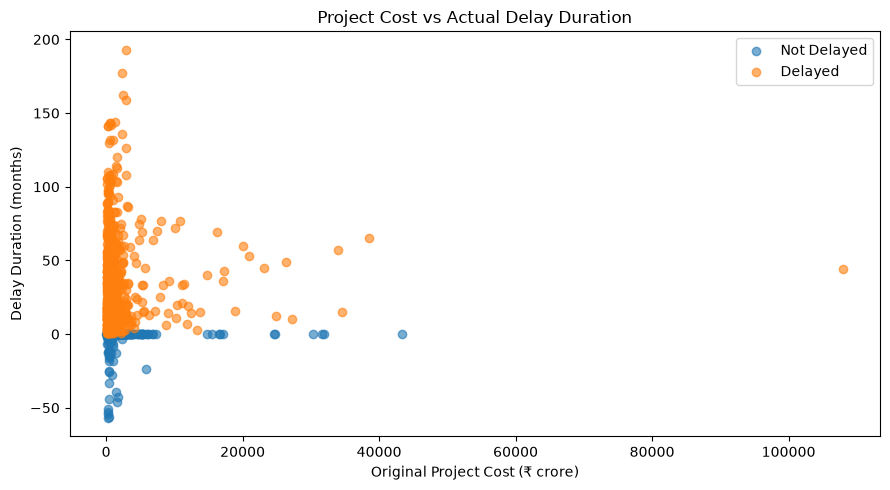

In [ ]:
#scatter plot
# Import libraries for plotting and data handling
import matplotlib.pyplot as plt
import pandas as pd

# Create a copy of the dataset to preserve the original data
scatter_df = df.copy()

# Convert project cost and delay months into numeric values
scatter_df["orig_cost_cr"] = pd.to_numeric(
    scatter_df["orig_cost_cr"],
    errors="coerce"
)

scatter_df["delay_months"] = pd.to_numeric(
    scatter_df["delay_months"],
    errors="coerce"
)

# Remove rows with missing values in the required columns
scatter_df = scatter_df.dropna(
    subset=["orig_cost_cr", "delay_months", "is_delayed"]
)

# Separate projects into delayed and non-delayed groups
not_delayed = scatter_df[scatter_df["is_delayed"] == 0]
delayed = scatter_df[scatter_df["is_delayed"] == 1]

# Create the scatter plot
plt.figure(figsize=(9, 5))

# Plot projects that were not delayed
plt.scatter(
    not_delayed["orig_cost_cr"],
    not_delayed["delay_months"],
    label="Not Delayed",
    alpha=0.6
)

# Plot projects that were delayed
plt.scatter(
    delayed["orig_cost_cr"],
    delayed["delay_months"],
    label="Delayed",
    alpha=0.6
)

# Add the graph title and axis labels
plt.title("Project Cost vs Actual Delay Duration")
plt.xlabel("Original Project Cost (₹ crore)")
plt.ylabel("Delay Duration (months)")

# Display the legend
plt.legend()

# Improve the layout and display the graph
plt.tight_layout()
plt.show()


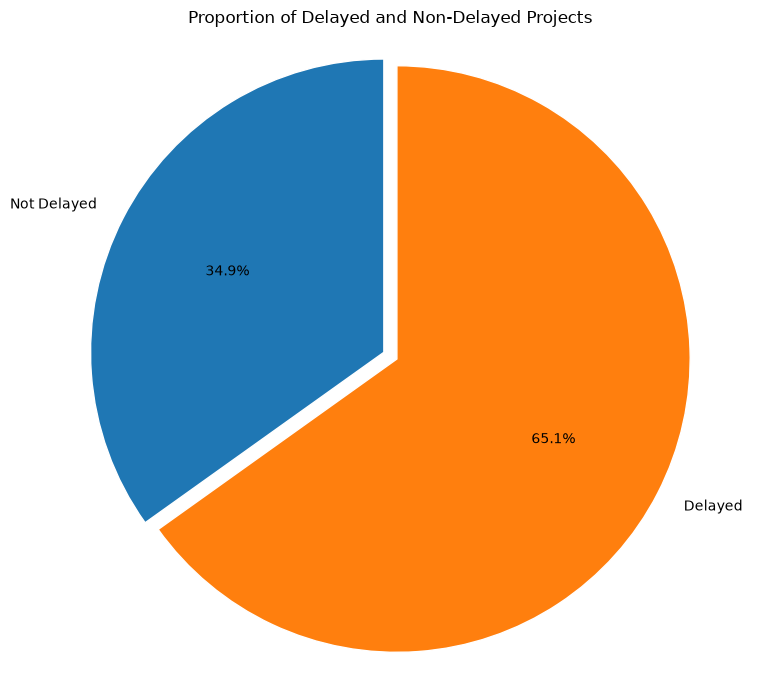

In [ ]:
#pie chart
#Import the plotting library
import matplotlib.pyplot as plt

# Count projects in each delay category
# 0 = Not Delayed, 1 = Delayed
status_counts = df["is_delayed"].value_counts().reindex(
    [0, 1],
    fill_value=0
)

# Define labels for the two categories
labels = ["Not Delayed", "Delayed"]

# Get the number of projects in each category
values = status_counts.values

# Create a figure for the pie chart
plt.figure(figsize=(8, 7))

# Draw the pie chart
plt.pie(
    values,
    labels=labels,
    autopct="%1.1f%%",  # Display percentages
    startangle=90,      # Start from the top
    explode=(0, 0.05),  # Slightly separate the delayed slice
    wedgeprops={"edgecolor": "white"}
)

# Add a descriptive title
plt.title("Proportion of Delayed and Non-Delayed Projects")

# Keep the pie chart circular
plt.axis("equal")

# Adjust spacing
plt.tight_layout()

# Display the chart
plt.show()

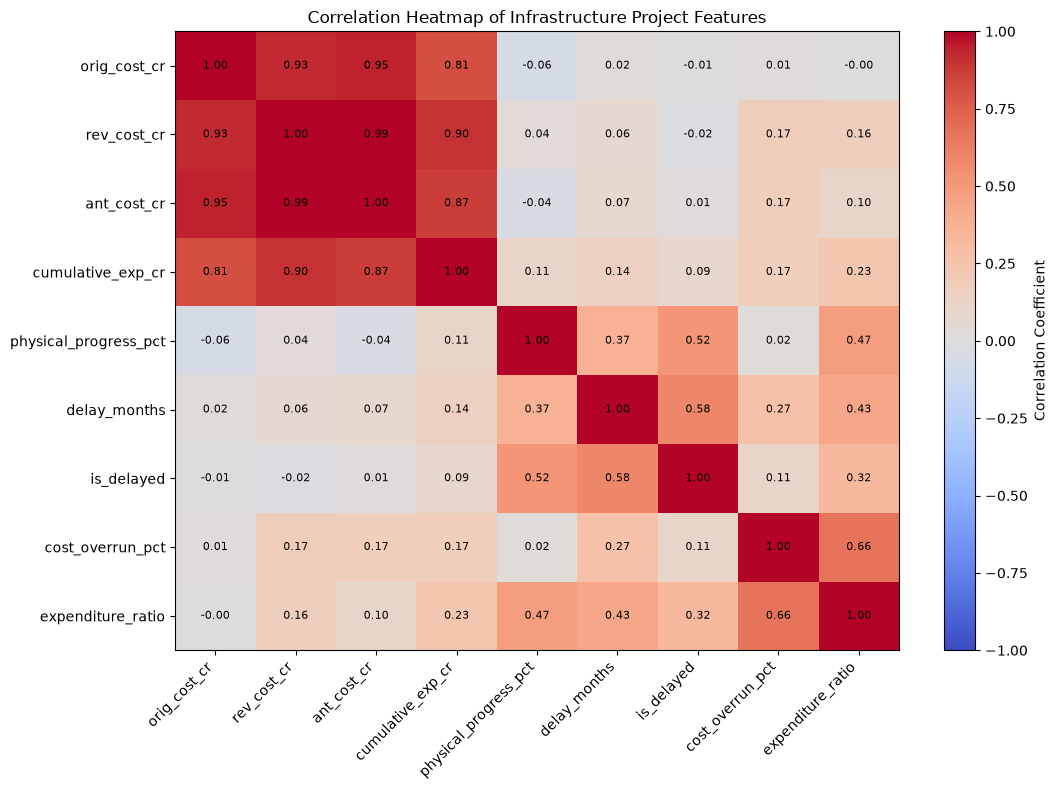

In [ ]:
#heatmap
# # Import libraries for numerical analysis and visualization
import matplotlib.pyplot as plt
import pandas as pd

# Select numerical project features available in your dataset
numeric_columns = [
    "orig_cost_cr",
    "rev_cost_cr",
    "ant_cost_cr",
    "cumulative_exp_cr",
    "physical_progress_pct",
    "delay_months",
    "is_delayed",
    "cost_overrun_pct",
    "expenditure_ratio"
]

# Keep only columns that exist in the dataset
numeric_columns = [
    column for column in numeric_columns
    if column in df.columns
]

# Convert selected columns to numeric values
# Invalid values will be replaced with NaN
numeric_df = df[numeric_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

# Calculate pairwise correlation coefficients
correlation = numeric_df.corr()

# Create the heatmap figure
fig, ax = plt.subplots(figsize=(11, 8))

# Display the correlation matrix using colors
# -1 represents negative correlation, +1 positive correlation
image = ax.imshow(
    correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="auto"
)

# Set feature names on both axes
ax.set_xticks(range(len(correlation.columns)))
ax.set_yticks(range(len(correlation.columns)))

# Rotate X-axis labels for readability
ax.set_xticklabels(
    correlation.columns,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(correlation.columns)

# Display the correlation value in each cell
for row in range(len(correlation.columns)):
    for column in range(len(correlation.columns)):

        # Retrieve the correlation coefficient
        value = correlation.iloc[row, column]

        # Write the value only if it is valid
        if pd.notna(value):
            ax.text(
                column,
                row,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=8
            )

# Add a color bar to explain the correlation scale
fig.colorbar(
    image,
    ax=ax,
    label="Correlation Coefficient"
)

# Add a title
ax.set_title("Correlation Heatmap of Infrastructure Project Features")

# Adjust the layout so labels are visible
plt.tight_layout()

# Display the heatmap
plt.show()

In [ ]:
# Create a copy of the original dataset
model_df = df.copy()

# Convert approval date into a proper date format.
# The dataset uses DD/MM/YY format, so dayfirst=True is required.
model_df["approval_date"] = pd.to_datetime(
    model_df["approval_date"],
    dayfirst=True,
    errors="coerce"
)

# Convert original commissioning date into a proper date format.
# This column follows the same DD/MM/YY format.
model_df["orig_commissioning_date"] = pd.to_datetime(
    model_df["orig_commissioning_date"],
    dayfirst=True,
    errors="coerce"
)

# Extract the approval year from the approval date
model_df["approval_year"] = model_df["approval_date"].dt.year

# Extract the approval month from the approval date
model_df["approval_month"] = model_df["approval_date"].dt.month

# Calculate the planned project duration in months
model_df["planned_duration_months"] = (
    (model_df["orig_commissioning_date"] - model_df["approval_date"]).dt.days / 30.44
)

# Display the newly created features
display(
    model_df[
        [
            "approval_year",
            "approval_month",
            "planned_duration_months"
        ]
    ].head()
)

# Verify that approval_month is no longer constant
print("Unique approval months:", sorted(model_df["approval_month"].dropna().unique().tolist()))


/var/folders/bb/7_bsg3s5637g5x8vz8pz722r0000gn/T/ipykernel_78875/1368673217.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  model_df["approval_date"] = pd.to_datetime(
/var/folders/bb/7_bsg3s5637g5x8vz8pz722r0000gn/T/ipykernel_78875/1368673217.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  model_df["orig_commissioning_date"] = pd.to_datetime(


,approval_year,approval_month,planned_duration_months
0,2013,10,59.001314
1,2019,3,72.010512
2,2017,3,33.015769
3,2018,3,30.059133
4,2017,11,23.981603


Unique approval months: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


In [ ]:
# Define the features used by the prediction model
features = [
    "sector",
    "agency",
    "state",
    "orig_cost_cr",
    "approval_year",
    "approval_month",
    "planned_duration_months"
]

# Create the input feature dataset
X = model_df[features].copy()

# Create the target variable
y = model_df["is_delayed"].copy()

# Display the selected input features
print("Input features:")
print(X.columns.tolist())

# Display the target variable
print("\nTarget:")
print("is_delayed")

# Display the number of rows and input features
print("\nDataset shape:")
print(X.shape)

Input features:
['sector', 'agency', 'state', 'orig_cost_cr', 'approval_year', 'approval_month', 'planned_duration_months']

Target:
is_delayed

Dataset shape:
(1477, 7)


In [ ]:
# Split the dataset into training and temporary sets
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Split the temporary set equally into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Display the training set size
print("Training set:", X_train.shape)

# Display the validation set size
print("Validation set:", X_val.shape)

# Display the test set size
print("Test set:", X_test.shape)

Training set: (1033, 7)
Validation set: (222, 7)
Test set: (222, 7)


In [ ]:
# Define the categorical features
categorical_features = [
    "sector",
    "agency",
    "state"
]

# Define the numerical features
numerical_features = [
    "orig_cost_cr",
    "approval_year",
    "approval_month",
    "planned_duration_months"
]

# Create the numerical preprocessing pipeline
numerical_pipeline = Pipeline(
    steps=[
        # Fill missing numerical values with the median
        ("imputer", SimpleImputer(strategy="median")),

        # Standardize numerical features
        ("scaler", StandardScaler())
    ]
)

# Create the categorical preprocessing pipeline
categorical_pipeline = Pipeline(
    steps=[
        # Fill missing categorical values with the most frequent value
        ("imputer", SimpleImputer(strategy="most_frequent")),

        # Convert categorical values into numerical features
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        # Apply numerical preprocessing
        ("numerical", numerical_pipeline, numerical_features),

        # Apply categorical preprocessing
        ("categorical", categorical_pipeline, categorical_features)
    ]
)

# Learn preprocessing rules from the training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same preprocessing to validation data
X_val_processed = preprocessor.transform(X_val)

# Apply the same preprocessing to test data
X_test_processed = preprocessor.transform(X_test)

# Display the number of features after preprocessing
print("Processed features:", X_train_processed.shape[1])

Processed features: 119


In [ ]:
# Create feature selection using the ANOVA F-test
selector = SelectKBest(
    score_func=f_classif,
    k=30
)

# Select the best 30 features using training data
X_train_selected = selector.fit_transform(
    X_train_processed,
    y_train
)

# Apply the selected features to validation data
X_val_selected = selector.transform(
    X_val_processed
)

# Apply the selected features to test data
X_test_selected = selector.transform(
    X_test_processed
)

# Display the number of features before selection
print(
    "Features before selection:",
    X_train_processed.shape[1]
)

# Display the number of features after selection
print(
    "Features after selection:",
    X_train_selected.shape[1]
)

Features before selection: 119
Features after selection: 30


In [ ]:
# Create the Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model using the selected training features
logistic_model.fit(
    X_train_selected,
    y_train
)

# Predict the validation classes
logistic_pred = logistic_model.predict(
    X_val_selected
)

# Calculate the probability of a project being delayed
logistic_prob = logistic_model.predict_proba(
    X_val_selected
)[:, 1]

# Display a training completion message
print("Logistic Regression training completed.")

Logistic Regression training completed.


In [ ]:
# Calculate the accuracy of the model
logistic_accuracy = accuracy_score(
    y_val,
    logistic_pred
)

# Calculate precision for delayed projects
logistic_precision = precision_score(
    y_val,
    logistic_pred,
    zero_division=0
)

# Calculate recall for delayed projects
logistic_recall = recall_score(
    y_val,
    logistic_pred,
    zero_division=0
)

# Calculate the F1 score
logistic_f1 = f1_score(
    y_val,
    logistic_pred,
    zero_division=0
)

# Calculate the ROC-AUC score
logistic_auc = roc_auc_score(
    y_val,
    logistic_prob
)

# Display the evaluation results
print("===== LOGISTIC REGRESSION =====")
print("Accuracy :", round(logistic_accuracy, 4))
print("Precision:", round(logistic_precision, 4))
print("Recall   :", round(logistic_recall, 4))
print("F1 Score :", round(logistic_f1, 4))
print("ROC-AUC  :", round(logistic_auc, 4))

===== LOGISTIC REGRESSION =====
Accuracy : 0.8919
Precision: 0.9007
Recall   : 0.9379
F1 Score : 0.9189
ROC-AUC  : 0.905


In [ ]:
# Create the Linear Discriminant Analysis model
lda_model = LinearDiscriminantAnalysis()

# Train the LDA model using the selected training features
lda_model.fit(
    X_train_selected,
    y_train
)

# Predict the validation classes
lda_pred = lda_model.predict(
    X_val_selected
)

# Calculate the probability of a project being delayed
lda_prob = lda_model.predict_proba(
    X_val_selected
)[:, 1]

# Display a training completion message
print("LDA training completed.")

LDA training completed.


In [ ]:
# Calculate the accuracy of LDA
lda_accuracy = accuracy_score(
    y_val,
    lda_pred
)

# Calculate precision for LDA
lda_precision = precision_score(
    y_val,
    lda_pred,
    zero_division=0
)

# Calculate recall for LDA
lda_recall = recall_score(
    y_val,
    lda_pred,
    zero_division=0
)

# Calculate the F1 score for LDA
lda_f1 = f1_score(
    y_val,
    lda_pred,
    zero_division=0
)

# Calculate the ROC-AUC score for LDA
lda_auc = roc_auc_score(
    y_val,
    lda_prob
)

# Display the LDA evaluation results
print("===== LDA =====")
print("Accuracy :", round(lda_accuracy, 4))
print("Precision:", round(lda_precision, 4))
print("Recall   :", round(lda_recall, 4))
print("F1 Score :", round(lda_f1, 4))
print("ROC-AUC  :", round(lda_auc, 4))

===== LDA =====
Accuracy : 0.8198
Precision: 0.8182
Recall   : 0.931
F1 Score : 0.871
ROC-AUC  : 0.8781


In [ ]:
# Create a table for comparing both models
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],

    # Store Logistic Regression results
    "Logistic Regression": [
        logistic_accuracy,
        logistic_precision,
        logistic_recall,
        logistic_f1,
        logistic_auc
    ],

    # Store LDA results
    "LDA": [
        lda_accuracy,
        lda_precision,
        lda_recall,
        lda_f1,
        lda_auc
    ]
})

# Round the model scores to four decimal places
comparison[
    ["Logistic Regression", "LDA"]
] = comparison[
    ["Logistic Regression", "LDA"]
].round(4)

# Display the comparison table
comparison

,Metric,Logistic Regression,LDA
0,Accuracy,0.8919,0.8198
1,Precision,0.9007,0.8182
2,Recall,0.9379,0.9310
3,F1 Score,0.9189,0.8710
4,ROC-AUC,0.9050,0.8781


In [ ]:
#MODEL EVALUATION 
# Predict the classes of unseen test projects
final_pred = logistic_model.predict(
    X_test_selected
)

# Calculate delay probabilities for unseen test projects
final_prob = logistic_model.predict_proba(
    X_test_selected
)[:, 1]

# Calculate final accuracy
final_accuracy = accuracy_score(
    y_test,
    final_pred
)

# Calculate final precision
final_precision = precision_score(
    y_test,
    final_pred,
    zero_division=0
)

# Calculate final recall
final_recall = recall_score(
    y_test,
    final_pred,
    zero_division=0
)

# Calculate final F1 score
final_f1 = f1_score(
    y_test,
    final_pred,
    zero_division=0
)

# Calculate final ROC-AUC
final_auc = roc_auc_score(
    y_test,
    final_prob
)

# Display the final test results
print("===== FINAL TEST RESULTS =====")
print("Accuracy :", round(final_accuracy, 4))
print("Precision:", round(final_precision, 4))
print("Recall   :", round(final_recall, 4))
print("F1 Score :", round(final_f1, 4))
print("ROC-AUC  :", round(final_auc, 4))

===== FINAL TEST RESULTS =====
Accuracy : 0.8468
Precision: 0.8873
Recall   : 0.875
F1 Score : 0.8811
ROC-AUC  : 0.9306


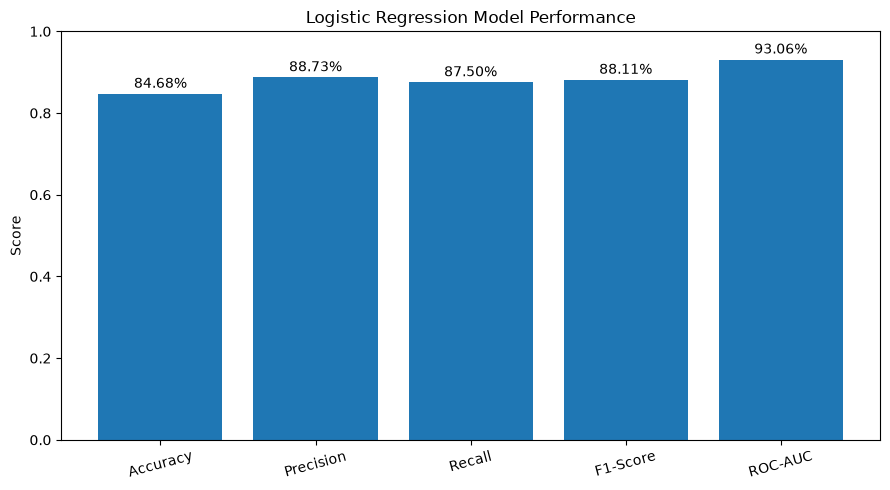

In [ ]:
import matplotlib.pyplot as plt

metrics = {
    "Accuracy": 0.8468,
    "Precision": 0.8873,
    "Recall": 0.8750,
    "F1-Score": 0.8811,
    "ROC-AUC": 0.9306
}

plt.figure(figsize=(9, 5))
bars = plt.bar(metrics.keys(), metrics.values())

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Logistic Regression Model Performance")
plt.xticks(rotation=15)

for bar, score in zip(bars, metrics.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        score + 0.015,
        f"{score:.2%}" if score != 0.8842 and score != 0.9389
        else f"{score:.4f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

Confusion Matrix:
[[ 62  16]
 [ 18 126]]


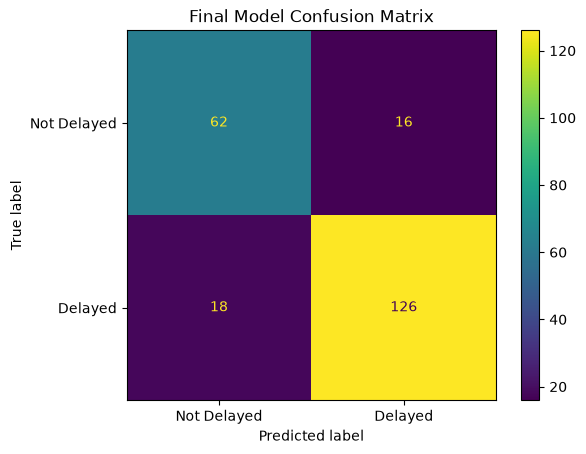

In [ ]:
# Calculate the confusion matrix
cm = confusion_matrix(
    y_test,
    final_pred
)

# Display the confusion matrix values
print("Confusion Matrix:")
print(cm)

# Create a visual confusion matrix
display_plot = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Delayed", "Delayed"]
)

# Plot the confusion matrix
display_plot.plot()

# Add a title to the graph
plt.title("Final Model Confusion Matrix")

# Display the graph
plt.show()

In [ ]:
# Convert the predicted delay probability into a score from 0 to 100
risk_score = final_prob * 100

# Make sure every risk score stays between 0 and 100
risk_score = np.clip(risk_score, 0, 100)

# Round the risk scores to two decimal places
risk_score = np.round(risk_score, 2)

# Display the first ten calculated risk scores
print("Sample Risk Scores:")
print(risk_score[:10])

Sample Risk Scores:
[40.08 81.26 94.13 40.19 91.94 37.64  6.58 95.19 99.96 48.06]


In [ ]:
# Create a function to convert a risk score into a risk category
def get_risk_level(score):

    # Assign LOW risk to scores from 0 to 30
    if score <= 30:
        return "LOW"

    # Assign MEDIUM risk to scores from 31 to 60
    elif score <= 60:
        return "MEDIUM"

    # Assign HIGH risk to scores from 61 to 80
    elif score <= 80:
        return "HIGH"

    # Assign CRITICAL risk to scores above 80
    else:
        return "CRITICAL"


# Apply the risk classification to every test project
risk_levels = [
    get_risk_level(score)
    for score in risk_score
]

# Display the first ten risk categories
print("Sample Risk Levels:")
print(risk_levels[:10])

Sample Risk Levels:
['MEDIUM', 'CRITICAL', 'CRITICAL', 'MEDIUM', 'CRITICAL', 'MEDIUM', 'LOW', 'CRITICAL', 'CRITICAL', 'MEDIUM']


In [ ]:
# Create a copy of the test projects
risk_results = X_test.copy()

# Add the actual delay status of each project
risk_results["actual_status"] = y_test.values

# Add the model's predicted delay status
risk_results["predicted_status"] = final_pred

# Convert predicted delay probability into percentage
risk_results["delay_probability"] = np.round(
    final_prob * 100,
    2
)

# Add the calculated risk score
risk_results["risk_score"] = risk_score

# Add the corresponding risk category
risk_results["risk_level"] = risk_levels

# Display the first ten prediction results
display(risk_results.head(10))

,sector,agency,state,orig_cost_cr,approval_year,approval_month,planned_duration_months,actual_status,predicted_status,delay_probability,risk_score,risk_level
1066,ROAD TRANSPORT AND HIGHWAYS,MoRTH,ODISHA,300.33,2022,1,38.961892,1,0,40.08,40.08,MEDIUM
414,ROAD TRANSPORT AND HIGHWAYS,NHAI,DELHI,1690.23,2020,11,36.957950,1,1,81.26,81.26,CRITICAL
818,ROAD TRANSPORT AND HIGHWAYS,MoRTH,MAHARASHTRA,223.35,2021,11,3.022339,0,1,94.13,94.13,CRITICAL
1445,CIVIL AVIATION,NHAI,UTTARAKHAND,314.31,2022,5,28.055191,1,0,40.19,40.19,MEDIUM
595,ROAD TRANSPORT AND HIGHWAYS,NHAI,GOA,317.90,2021,3,7.030223,1,1,91.94,91.94,CRITICAL
630,URBAN DEVELOPMENT,AAI,KERALA,484.57,2023,6,27.036794,0,0,37.64,37.64,MEDIUM
22,POWER,HPCL,ANDHRA PRADESH,193.00,2024,7,35.972405,0,0,6.58,6.58,LOW
887,ROAD TRANSPORT AND HIGHWAYS,NHIDCL,MANIPUR,483.87,2021,7,19.973719,1,1,95.19,95.19,CRITICAL
1084,ROAD TRANSPORT AND HIGHWAYS,NR,DELHI,404.00,2009,6,86.005256,1,1,99.96,99.96,CRITICAL
954,RAILWAYS,PGCIL,GUJARAT,186.19,2022,7,31.997372,0,0,48.06,48.06,MEDIUM


In [ ]:
# Count the number of projects in each risk category
risk_distribution = risk_results["risk_level"].value_counts()

# Display the risk category distribution
print(risk_distribution)

risk_level
CRITICAL    91
MEDIUM      65
LOW         38
HIGH        28
Name: count, dtype: int64


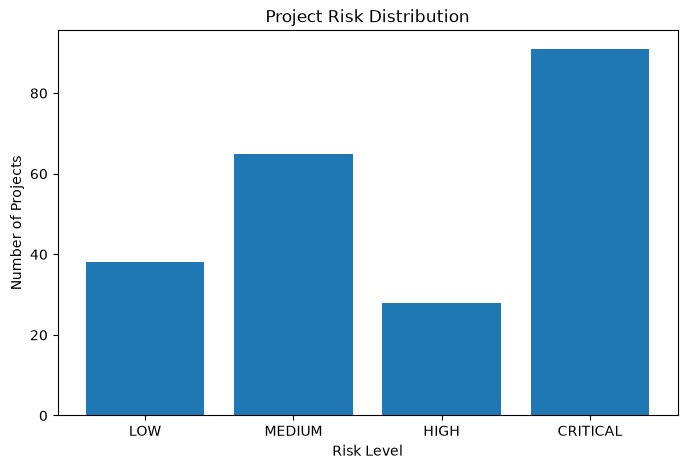

In [ ]:
# Define the order of the risk categories
risk_order = [
    "LOW",
    "MEDIUM",
    "HIGH",
    "CRITICAL"
]

# Count projects according to the defined risk order
risk_counts = (
    risk_results["risk_level"]
    .value_counts()
    .reindex(risk_order, fill_value=0)
)

# Set the size of the graph
plt.figure(figsize=(8, 5))

# Create a bar chart of the risk distribution
plt.bar(
    risk_counts.index,
    risk_counts.values
)

# Label the x-axis
plt.xlabel("Risk Level")

# Label the y-axis
plt.ylabel("Number of Projects")

# Add the graph title
plt.title("Project Risk Distribution")

# Display the graph
plt.show()

In [ ]:
# Select projects classified as HIGH or CRITICAL risk
high_risk_projects = risk_results[
    risk_results["risk_level"].isin(
        ["HIGH", "CRITICAL"]
    )
]

# Sort high-risk projects from highest to lowest risk
high_risk_projects = high_risk_projects.sort_values(
    "risk_score",
    ascending=False
)

# Display the high-risk projects
display(high_risk_projects)

,sector,agency,state,orig_cost_cr,approval_year,approval_month,planned_duration_months,actual_status,predicted_status,delay_probability,risk_score,risk_level
203,ROAD TRANSPORT AND HIGHWAYS,NHAI,BIHAR,575.00,2011,1,29.960578,1,1,99.99,99.99,CRITICAL
143,ROAD TRANSPORT AND HIGHWAYS,NHIDCL,ASSAM,520.01,1991,1,340.932983,1,1,99.96,99.96,CRITICAL
1199,POWER,BPCL,TAMIL NADU,678.00,2012,11,51.018397,1,1,99.96,99.96,CRITICAL
1084,ROAD TRANSPORT AND HIGHWAYS,NR,DELHI,404.00,2009,6,86.005256,1,1,99.96,99.96,CRITICAL
587,ROAD TRANSPORT AND HIGHWAYS,MoRTH,GOA,314.90,2016,11,3.942181,1,1,99.91,99.91,CRITICAL
...,...,...,...,...,...,...,...,...,...,...,...,...
776,ROAD TRANSPORT AND HIGHWAYS,CR,MAHARASHTRA,736.44,1999,2,336.892247,0,1,61.93,61.93,HIGH
605,ROAD TRANSPORT AND HIGHWAYS,NHAI,GOA,294.62,2022,3,24.014455,1,1,61.64,61.64,HIGH
1403,ROAD TRANSPORT AND HIGHWAYS,NHAI,BIHAR,2555.50,2021,12,38.961892,0,1,61.49,61.49,HIGH
698,ROAD TRANSPORT AND HIGHWAYS,NHAI,GUJARAT,1001.69,2021,1,38.961892,0,1,61.49,61.49,HIGH


In [ ]:
# Select the ten projects with the highest risk scores
top_risk_projects = high_risk_projects.head(10)

# Display the top ten high-risk projects
display(top_risk_projects)

,sector,agency,state,orig_cost_cr,approval_year,approval_month,planned_duration_months,actual_status,predicted_status,delay_probability,risk_score,risk_level
203,ROAD TRANSPORT AND HIGHWAYS,NHAI,BIHAR,575.00,2011,1,29.960578,1,1,99.99,99.99,CRITICAL
143,ROAD TRANSPORT AND HIGHWAYS,NHIDCL,ASSAM,520.01,1991,1,340.932983,1,1,99.96,99.96,CRITICAL
1199,POWER,BPCL,TAMIL NADU,678.00,2012,11,51.018397,1,1,99.96,99.96,CRITICAL
1084,ROAD TRANSPORT AND HIGHWAYS,NR,DELHI,404.00,2009,6,86.005256,1,1,99.96,99.96,CRITICAL
587,ROAD TRANSPORT AND HIGHWAYS,MoRTH,GOA,314.90,2016,11,3.942181,1,1,99.91,99.91,CRITICAL
1472,POWER,NTPC,WEST BENGAL,1381.84,2014,9,59.986859,1,1,99.85,99.85,CRITICAL
740,PETROLEUM,ONGC,MAHARASHTRA,3190.69,2015,12,27.989488,1,1,99.83,99.83,CRITICAL
0,ROAD TRANSPORT AND HIGHWAYS,AAI,ANDAMAN AND NICOBAR ISLANDS,417.23,2013,10,59.001314,1,1,99.79,99.79,CRITICAL
947,POWER,PGCIL,GUJARAT,4754.42,2014,12,47.996058,1,1,99.79,99.79,CRITICAL
640,ROAD TRANSPORT AND HIGHWAYS,MoRTH,KERALA,380.76,2017,2,6.964520,1,1,99.75,99.75,CRITICAL


## Final Model Summary

The final model uses Logistic Regression to predict whether an infrastructure
project is likely to experience a delay.

The model uses sector, agency, state, original project cost, approval year,
approval month and planned project duration as input features.

The data is preprocessed using missing-value handling, categorical encoding
and numerical standardization.

SelectKBest with the ANOVA F-test is used to select the 30 most relevant
features.

Linear Discriminant Analysis (LDA) is used as a comparison model.

The final Logistic Regression model is evaluated using Accuracy, Precision,
Recall, F1 Score and ROC-AUC.

The predicted probability of delay is converted into a 0–100 risk score.

The risk score is classified into LOW, MEDIUM, HIGH and CRITICAL categories.

In [ ]:
# Import joblib to save the trained machine learning components
import joblib

# Store the preprocessing, feature selection and model components together
model_package = {
    "preprocessor": preprocessor,
    "selector": selector,
    "model": logistic_model,
    "features": features
}

# Save the complete model package for later predictions
joblib.dump(
    model_package,
    "land_delay_model.pkl"
)

# Confirm that the model file was created
print("Model saved successfully as land_delay_model.pkl")

Model saved successfully as land_delay_model.pkl


In [ ]:
# Check that the saved model file can be loaded correctly
loaded_package = joblib.load("land_delay_model.pkl")

# Display the components stored inside the model package
print("Saved components:")
print(loaded_package.keys())

# Display the features used by the model
print("\nModel features:")
print(loaded_package["features"])

Saved components:
dict_keys(['preprocessor', 'selector', 'model', 'features'])

Model features:
['sector', 'agency', 'state', 'orig_cost_cr', 'approval_year', 'approval_month', 'planned_duration_months']


In [ ]:
# Load the trained preprocessing pipeline
saved_preprocessor = loaded_package["preprocessor"]

# Load the trained feature selector
saved_selector = loaded_package["selector"]

# Load the trained Logistic Regression model
saved_model = loaded_package["model"]

# Take one real project from the test dataset
sample_project = X_test.iloc[[0]]

# Preprocess the project using the saved preprocessing pipeline
sample_processed = saved_preprocessor.transform(sample_project)

# Select the required features
sample_selected = saved_selector.transform(sample_processed)

# Predict whether the project is delayed
sample_prediction = saved_model.predict(sample_selected)

# Calculate the probability of delay
sample_probability = saved_model.predict_proba(sample_selected)[0][1]

# Convert the probability into a percentage
sample_probability = round(sample_probability * 100, 2)

# Display the prediction
print("Predicted Status:", sample_prediction[0])
print("Delay Probability:", sample_probability, "%")

Predicted Status: 0
Delay Probability: 40.08 %


# Final Summary and Model Evaluation
## Predictive Analytics System for Early Detection of Land Acquisition and Infrastructure Project Delays

### 1. Project Objective

The objective of this project is to develop a machine learning system that predicts whether an infrastructure project is likely to be delayed. The system uses historical project information to identify potential delay risks and support early planning, monitoring, and decision-making.

### 2. Dataset and Target Variable

The project uses the `SIH26017_MoSPI_1477_projects.csv` dataset.

- **Target variable:** `is_delayed`
- **Input features:** Sector, implementing agency, state, original project cost, approval year, approval month, and planned project duration.
- **Prediction output:** Delayed or Not Delayed.

### 3. Implementation Steps

1. **Data Loading:** Imported the dataset using Pandas.
2. **Data Exploration:** Examined the dataset structure, column types, missing values, and distribution of the target variable.
3. **Data Preprocessing:** Handled missing values using appropriate imputation techniques.
4. **Feature Preparation:** Separated the input features from the target variable and prepared numerical and categorical columns.
5. **Feature Scaling and Encoding:** Applied standard scaling to numerical features and one-hot encoding to categorical features.
6. **Feature Selection:** Used SelectKBest with the ANOVA F-test (`f_classif`) to select relevant features.
7. **Model Training:** Trained a Logistic Regression classifier to predict project delay status.
8. **Model Evaluation:** Evaluated the model using accuracy, precision, recall, F1-score, and ROC-AUC.
9. **Model Saving:** Saved the trained model and preprocessing components for reuse in the prediction script and web dashboard.

### 4. Model Performance Results

| Evaluation Metric | Result |
|---|---:|
| Accuracy | 84.68% |
| Precision | 88.73% |
| Recall | 87.50% |
| F1-Score | 0.8811 |
| ROC-AUC | 0.9306 |

### 5. Interpretation of Results

- **Accuracy — 84.68%:** The model correctly classified approximately 84.68% of the evaluated project records.
- **Precision — 88.73%:** Of the projects predicted as delayed, approximately 88.73% were actually delayed.
- **Recall — 87.50%:** The model identified approximately 87.50% of the projects that were actually delayed.
- **F1-Score — 0.8811:** This indicates a strong balance between precision and recall.
- **ROC-AUC — 0.9306:** This indicates strong ability to distinguish between delayed and non-delayed projects across different classification thresholds.

### 6. Practical Application

The trained model is integrated into a prediction system where project details can be entered to obtain a delay prediction and associated risk information. The dashboard presents the prediction in an understandable format, helping users identify projects that may require closer monitoring and further assessment.

### 7. Limitations

- Predictions depend on the quality, completeness, and representativeness of the historical dataset.
- The model identifies statistical patterns and does not establish the actual cause of an individual project's delay.
- Prediction performance on future projects may differ from the reported evaluation results.
- The system should support human decision-making rather than replace administrative assessment.

### 8. Conclusion

This project demonstrates how machine learning can be applied to infrastructure project data for the early identification of potential delays. The Logistic Regression model achieved an accuracy of **84.68%**, an F1-score of **0.8811**, and an ROC-AUC of **0.9306** in the reported evaluation.

The implementation combines data preprocessing, feature selection, model training, performance evaluation, and model deployment into a practical predictive analytics workflow. The system can help project-monitoring authorities prioritize projects for further investigation and take preventive action where necessary. Its predictions should be treated as decision-support indicators, not guarantees of future project outcomes.
